# Phase 7: Final Model Evaluation

## Objective
Evaluate optimized machine learning models on the
independent 2025 test dataset.

## Experimental Setup
- Training: 2021–2024
- Testing: 2025
- Models: Seasonal Naive, Random Forest, XGBoost
- Metrics: RMSE, MAE

In [1]:
# Step 7.1: Prepare final training and test datasets

from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Locate project directory
project = Path.cwd()

if not (project / "data_processed").exists():
    project = project.parent

ml_df = pd.read_csv(
    project / "data_processed" / "pjm_rto_ml_features.csv"
)

# Convert timestamps
ml_df["forecast_origin"] = pd.to_datetime(
    ml_df["forecast_origin"], utc=True
)

ml_df["datetime_utc"] = pd.to_datetime(
    ml_df["datetime_utc"], utc=True
)

# Define local forecast year
ml_df["forecast_year"] = (
    ml_df["forecast_origin"]
    .dt.tz_convert("America/New_York")
    .dt.year
)

# Independent 2025 test data
test = ml_df[
    ml_df["forecast_year"] == 2025
].copy()

# Prevent training targets from overlapping the test period
test_start = test["forecast_origin"].min()

train_final = ml_df[
    (ml_df["forecast_origin"] < test_start) &
    (ml_df["datetime_utc"] < test_start)
].copy()

# Final ML features
features = [
    "hour", "day_of_week", "month",
    "is_weekend", "horizon",
    "lag_24", "lag_48", "lag_168",
    "rolling_mean_24", "rolling_std_24",
    "rolling_mean_168", "rolling_std_168"
]

X_train_final = train_final[features]
y_train_final = train_final["mw"]

X_test = test[features]
y_test = test["mw"]

print("Final Training:", X_train_final.shape)
print("Final Test:", X_test.shape)

print("\nTraining target ends:",
      train_final["datetime_utc"].max())

print("First test forecast:",
      test_start)

print("\nNo target overlap:",
      train_final["datetime_utc"].max() < test_start)

print("\nMissing feature values:",
      X_train_final.isna().sum().sum(),
      X_test.isna().sum().sum())

Final Training: (34896, 12)
Final Test: (8760, 12)

Training target ends: 2025-01-01 04:00:00+00:00
First test forecast: 2025-01-01 05:00:00+00:00

No target overlap: True

Missing feature values: 0 0


In [2]:
# Step 7.2: Train final optimized models

rf_final = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

xgb_final = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Fit using 2021–2024 training data
rf_final.fit(X_train_final, y_train_final)
xgb_final.fit(X_train_final, y_train_final)

# Predict 2025 test data
rf_test_pred = rf_final.predict(X_test)
xgb_test_pred = xgb_final.predict(X_test)

print("Final models trained successfully!")

Final models trained successfully!


In [3]:
# Step 7.3: Final test evaluation

# Seasonal Naive predictions
naive_test_pred = test["lag_24"].to_numpy()

predictions = {
    "Seasonal Naive": naive_test_pred,
    "Random Forest": rf_test_pred,
    "XGBoost": xgb_test_pred
}

final_results = []

for name, pred in predictions.items():

    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)

    final_results.append({
        "Model": name,
        "Test RMSE": rmse,
        "Test MAE": mae
    })

final_results = pd.DataFrame(final_results)

display(
    final_results.sort_values("Test RMSE").round(2)
)

,Model,Test RMSE,Test MAE
2,XGBoost,5273.58,3870.37
1,Random Forest,5543.62,4012.76
0,Seasonal Naive,6652.94,5023.84


In [4]:
# Step 7.4: Compare improvement over naive baseline

naive_rmse = final_results.loc[
    final_results["Model"] == "Seasonal Naive",
    "Test RMSE"
].iloc[0]

final_results["RMSE Improvement (%)"] = (
    (naive_rmse - final_results["Test RMSE"])
    / naive_rmse * 100
)

display(
    final_results.sort_values("Test RMSE").round(2)
)

,Model,Test RMSE,Test MAE,RMSE Improvement (%)
2,XGBoost,5273.58,3870.37,20.73
1,Random Forest,5543.62,4012.76,16.67
0,Seasonal Naive,6652.94,5023.84,0.00


### Final Model Evaluation

XGBoost achieved the best performance on the independent 2025 test set, with an RMSE of 5,273.58 MW and an MAE of 3,870.37 MW. This represents a 20.73% reduction in RMSE compared with the seasonal naive baseline. Random Forest also improved upon the baseline, but XGBoost achieved the lowest prediction error. These results demonstrate the effectiveness of tree-based ensemble learning for day-ahead electricity demand forecasting using historical load features.

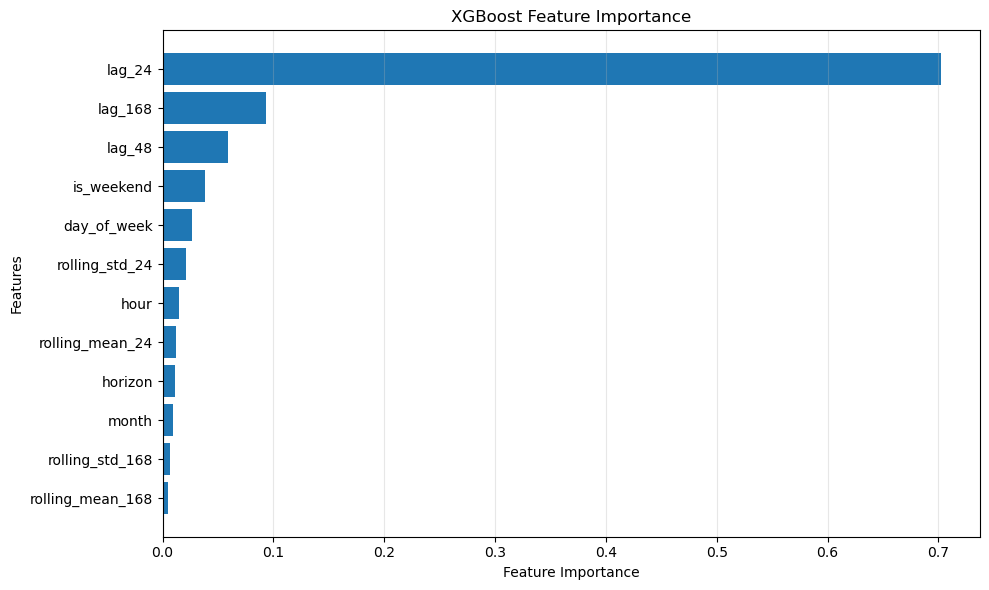

,Feature,Importance
5,lag_24,0.7023
7,lag_168,0.0932
6,lag_48,0.0589
3,is_weekend,0.0383
1,day_of_week,0.0265
9,rolling_std_24,0.0215
0,hour,0.0145
8,rolling_mean_24,0.0120
4,horizon,0.0113
2,month,0.0094


In [5]:
# Step 8.1: XGBoost Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_final.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

display(
    importance_df.sort_values(
        "Importance", ascending=False
    ).round(4)
)

### XGBoost Feature Importance

Historical load features dominate the model's feature importance. `lag_24` has the highest importance (0.7023), followed by `lag_168` (0.0932) and `lag_48` (0.0589). Together, these three features account for approximately 85.4% of the model's normalized importance. This is consistent with the feature engineering experiments, where adding historical load features substantially reduced forecasting error.

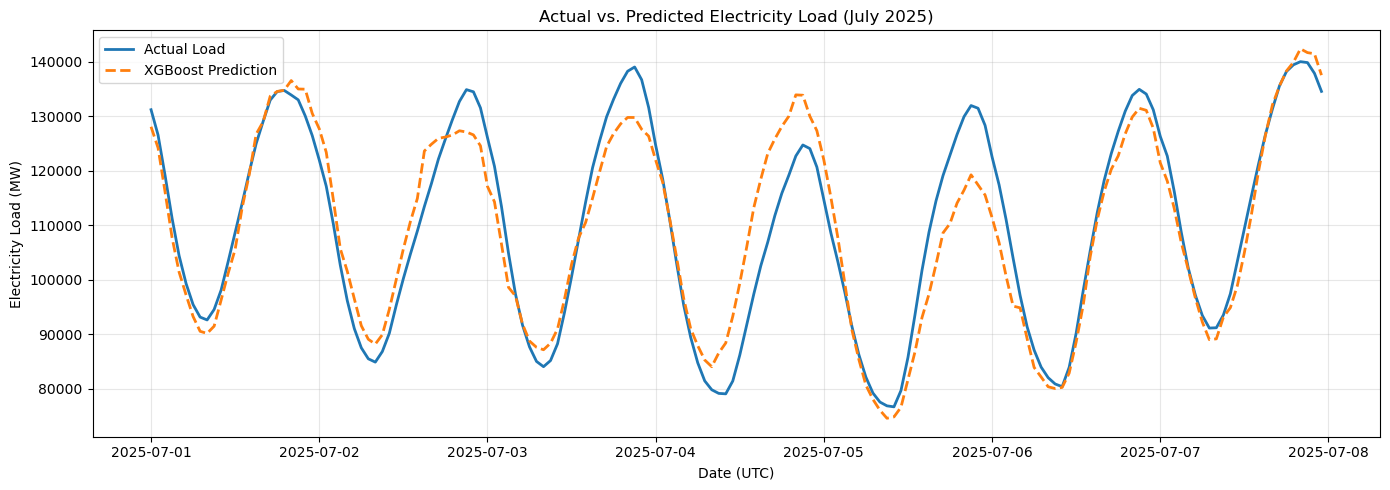

In [6]:
# Step 8.2: Actual vs. Predicted Electricity Load

import matplotlib.pyplot as plt

# Prepare prediction results
prediction_df = test[
    ["datetime_utc", "mw"]
].copy()

prediction_df["xgb_pred"] = xgb_test_pred

prediction_df = prediction_df.sort_values(
    "datetime_utc"
).reset_index(drop=True)

# Plot one representative week (first week of July 2025)
start_date = pd.Timestamp("2025-07-01", tz="UTC")
end_date = pd.Timestamp("2025-07-08", tz="UTC")

week_data = prediction_df[
    (prediction_df["datetime_utc"] >= start_date) &
    (prediction_df["datetime_utc"] < end_date)
]

plt.figure(figsize=(14, 5))

plt.plot(
    week_data["datetime_utc"],
    week_data["mw"],
    label="Actual Load",
    linewidth=2
)

plt.plot(
    week_data["datetime_utc"],
    week_data["xgb_pred"],
    label="XGBoost Prediction",
    linewidth=2,
    linestyle="--"
)

plt.title("Actual vs. Predicted Electricity Load (July 2025)")
plt.xlabel("Date (UTC)")
plt.ylabel("Electricity Load (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Actual vs. Predicted Electricity Load

The XGBoost predictions generally follow the daily fluctuations in actual electricity demand. However, the model underestimates some peak loads and overestimates demand during certain periods. These differences suggest that the model captures regular demand patterns reasonably well but has more difficulty predicting larger fluctuations.

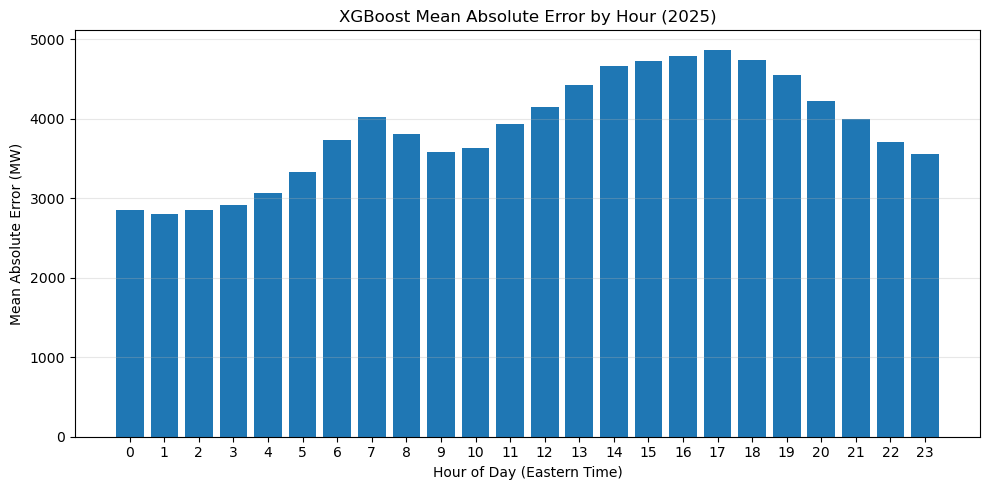

Highest MAE hour: 17
Lowest MAE hour: 1


hour
0     2854.18
1     2807.08
2     2848.26
3     2917.48
4     3061.53
5     3331.28
6     3731.73
7     4016.15
8     3800.93
9     3582.25
10    3631.25
11    3935.35
12    4149.17
13    4428.79
14    4659.57
15    4719.27
16    4781.64
17    4867.17
18    4742.93
19    4547.31
20    4219.40
21    3997.35
22    3700.77
23    3560.04
Name: absolute_error, dtype: float64

In [7]:
# Step 8.3: Hourly Error Analysis

# Add local time and prediction errors
prediction_df["datetime_ept"] = (
    prediction_df["datetime_utc"]
    .dt.tz_convert("America/New_York")
)

prediction_df["hour"] = prediction_df["datetime_ept"].dt.hour

prediction_df["error"] = (
    prediction_df["mw"] - prediction_df["xgb_pred"]
)

prediction_df["absolute_error"] = prediction_df["error"].abs()

# Calculate MAE by hour
hourly_errors = (
    prediction_df.groupby("hour")["absolute_error"]
    .mean()
)

plt.figure(figsize=(10, 5))

plt.bar(hourly_errors.index, hourly_errors.values)

plt.title("XGBoost Mean Absolute Error by Hour (2025)")
plt.xlabel("Hour of Day (Eastern Time)")
plt.ylabel("Mean Absolute Error (MW)")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Highest MAE hour:", hourly_errors.idxmax())
print("Lowest MAE hour:", hourly_errors.idxmin())

display(hourly_errors.round(2))

### Hourly Error Analysis

Forecasting errors vary across the day, with the lowest MAE at 1 AM (2,807.08 MW) and the highest at 5 PM (4,867.17 MW). Errors generally increase during the afternoon and early evening, suggesting that higher-demand periods are more challenging for the model in terms of absolute prediction error.

,Season,RMSE,MAE
0,Winter,6798.60,5391.69
1,Spring,3766.66,2831.74
2,Summer,6170.20,4642.86
3,Fall,3605.76,2634.83


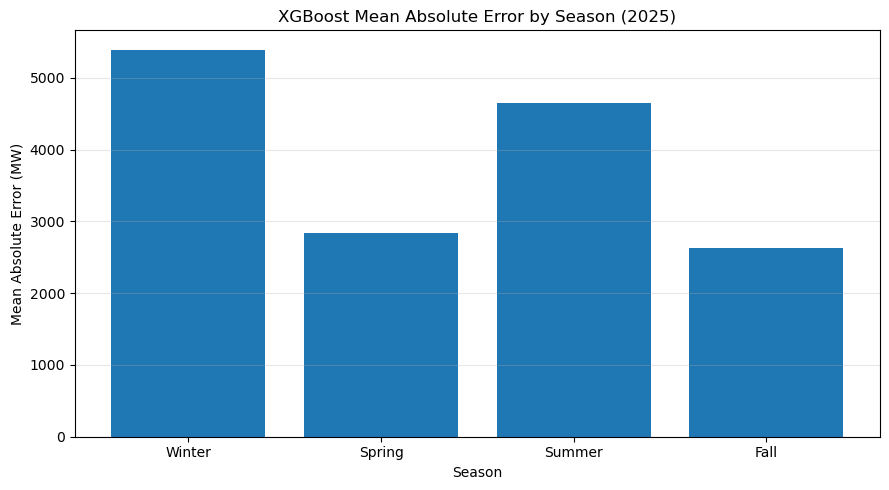

In [8]:
# Step 8.4: Seasonal Error Analysis

# Extract month from Eastern Time
prediction_df["month"] = prediction_df["datetime_ept"].dt.month

# Define seasons
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"
}

prediction_df["season"] = prediction_df["month"].map(season_map)

# Calculate RMSE and MAE for each season
seasonal_results = []

for season in ["Winter", "Spring", "Summer", "Fall"]:

    subset = prediction_df[
        prediction_df["season"] == season
    ]

    rmse = np.sqrt(
        mean_squared_error(subset["mw"], subset["xgb_pred"])
    )

    mae = mean_absolute_error(
        subset["mw"], subset["xgb_pred"]
    )

    seasonal_results.append({
        "Season": season,
        "RMSE": rmse,
        "MAE": mae
    })

seasonal_results = pd.DataFrame(seasonal_results)

display(seasonal_results.round(2))

# Visualize seasonal errors
plt.figure(figsize=(9, 5))

plt.bar(
    seasonal_results["Season"],
    seasonal_results["MAE"]
)

plt.title("XGBoost Mean Absolute Error by Season (2025)")
plt.xlabel("Season")
plt.ylabel("Mean Absolute Error (MW)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Seasonal Error Analysis

Forecasting errors vary considerably across seasons. Winter has the highest MAE (5,391.69 MW), followed by summer (4,642.86 MW), while fall has the lowest MAE (2,634.83 MW). The larger errors in winter and summer suggest that the model has more difficulty predicting demand during periods of greater seasonal variability. Incorporating weather-related features may help address this limitation in future work.

Residual Summary:
count     8760.00
mean      1429.49
std       5076.43
min     -17999.40
25%      -1712.84
50%        884.31
75%       4048.03
max      29012.16
Name: residual, dtype: float64

Mean Residual: 1429.49


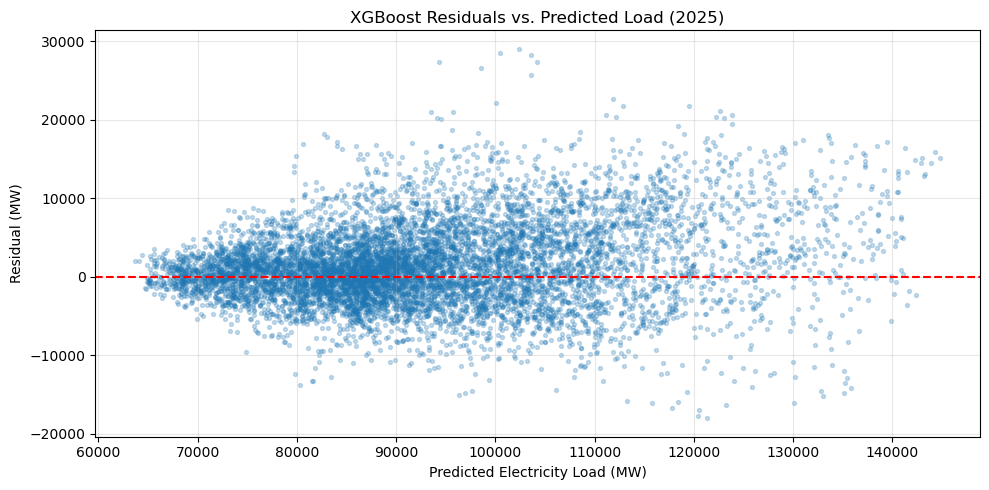

In [9]:
# Step 8.5: Residual Analysis

import matplotlib.pyplot as plt
import numpy as np

# Residual = Actual - Predicted
prediction_df["residual"] = (
    prediction_df["mw"] - prediction_df["xgb_pred"]
)

# Summary statistics
print("Residual Summary:")
print(prediction_df["residual"].describe().round(2))

print("\nMean Residual:",
      round(prediction_df["residual"].mean(), 2))

# Residual scatter plot
plt.figure(figsize=(10, 5))

plt.scatter(
    prediction_df["xgb_pred"],
    prediction_df["residual"],
    alpha=0.25,
    s=8
)

plt.axhline(0, linestyle="--", color="red")

plt.title("XGBoost Residuals vs. Predicted Load (2025)")
plt.xlabel("Predicted Electricity Load (MW)")
plt.ylabel("Residual (MW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Residual Analysis

The XGBoost model has a positive mean residual of 1,429.49 MW on the 2025 test set, indicating an overall tendency to underestimate electricity demand. Residuals also appear more dispersed at higher predicted load levels, suggesting possible heteroscedasticity. These findings highlight limitations in capturing changes in demand levels and larger load fluctuations.

In [10]:
# Step 9.2.1: Export final model comparison results

from pathlib import Path

# Locate project root
project = Path.cwd()

if not (project / "results").exists():
    project = project.parent

tables_dir = project / "results" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

# Save final test results
final_results.to_csv(
    tables_dir / "final_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully!")
print("Location:", tables_dir / "final_model_comparison.csv")

display(final_results.round(2))

Final model comparison saved successfully!
Location: /Users/jamella/Desktop/27fall/ml/data_source/electricity-demand-forecasting/results/tables/final_model_comparison.csv


,Model,Test RMSE,Test MAE,RMSE Improvement (%)
0,Seasonal Naive,6652.94,5023.84,0.00
1,Random Forest,5543.62,4012.76,16.67
2,XGBoost,5273.58,3870.37,20.73


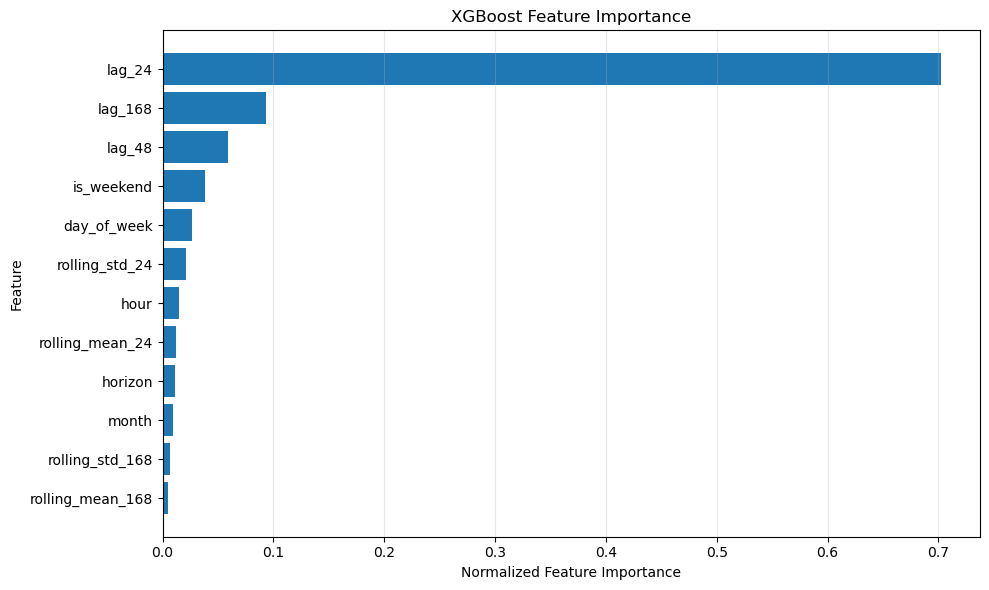

Feature importance CSV and PNG saved successfully!


In [11]:
# Step 9.2.2: Export XGBoost Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Create output directories
figures_dir = project / "results" / "figures"
tables_dir = project / "results" / "tables"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Extract feature importance
importance_export = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_final.feature_importances_
}).sort_values("Importance", ascending=False)

# Save CSV
importance_export.to_csv(
    tables_dir / "xgboost_feature_importance.csv",
    index=False
)

# Create figure
plt.figure(figsize=(10, 6))

plt.barh(
    importance_export["Feature"][::-1],
    importance_export["Importance"][::-1]
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Normalized Feature Importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# Save high-resolution PNG
plt.savefig(
    figures_dir / "xgboost_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance CSV and PNG saved successfully!")

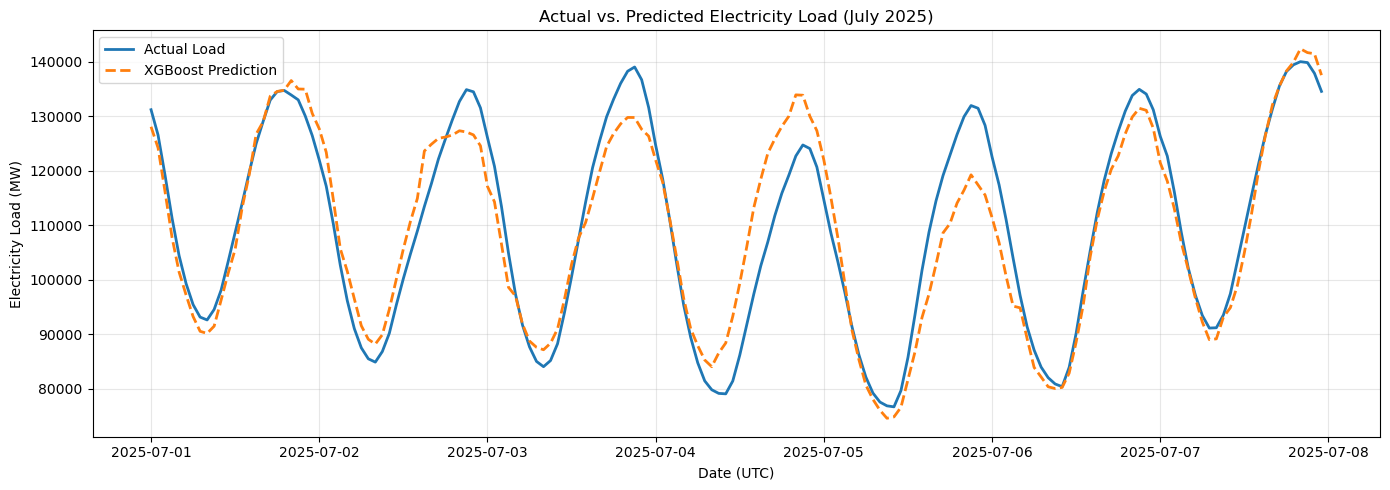

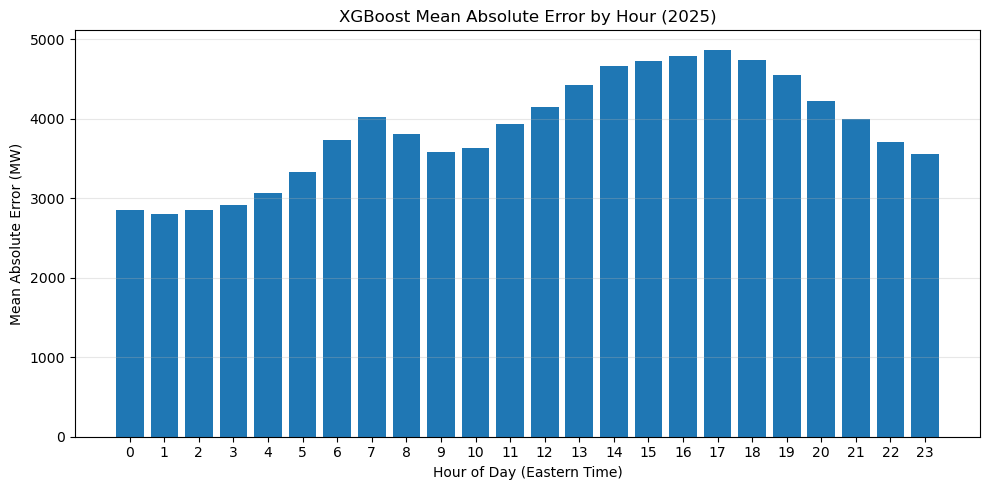

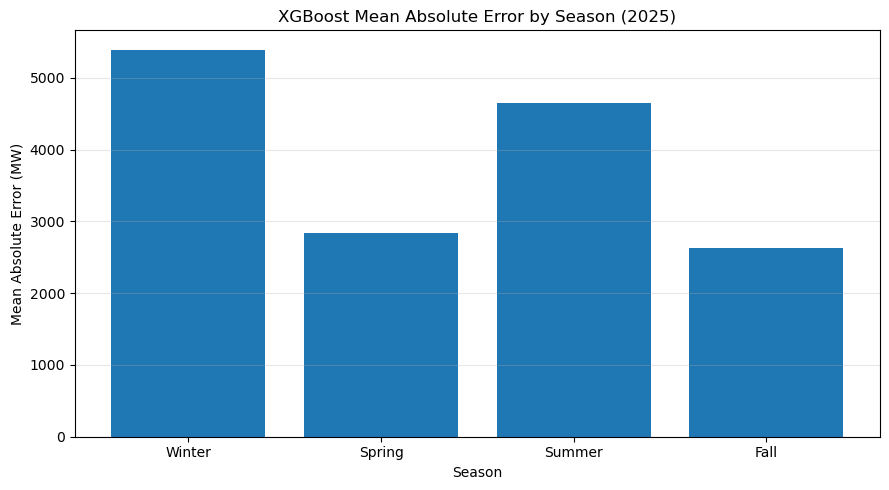

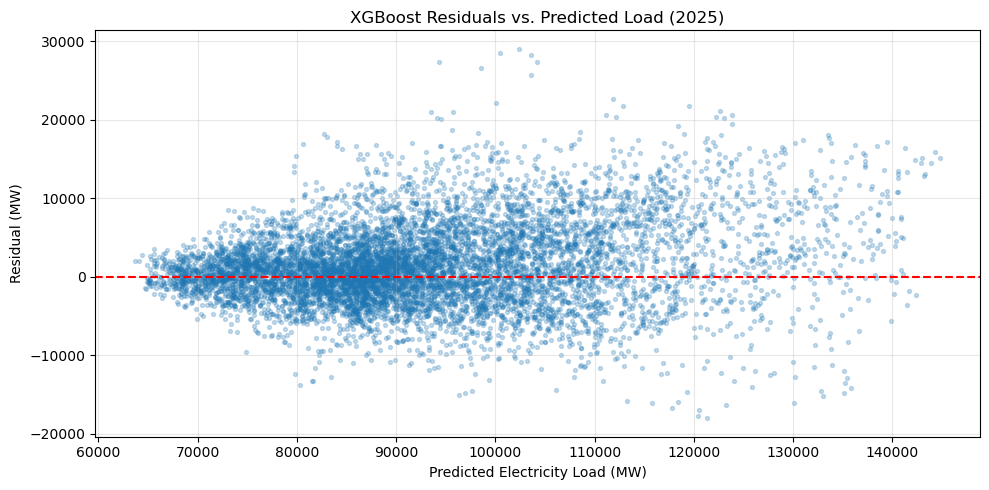

All prediction and error analysis files exported!


In [12]:
# Step 9.2.3: Export Prediction and Error Analysis

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate project root
project = Path.cwd()
if not (project / "results").exists():
    project = project.parent

figures_dir = project / "results" / "figures"
tables_dir = project / "results" / "tables"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Prepare prediction data
export_df = test[
    ["datetime_utc", "mw"]
].copy()

export_df["datetime_utc"] = pd.to_datetime(
    export_df["datetime_utc"], utc=True
)

export_df["xgb_pred"] = xgb_test_pred
export_df["datetime_ept"] = (
    export_df["datetime_utc"].dt.tz_convert("America/New_York")
)

export_df["hour"] = export_df["datetime_ept"].dt.hour
export_df["month"] = export_df["datetime_ept"].dt.month
export_df["residual"] = export_df["mw"] - export_df["xgb_pred"]
export_df["absolute_error"] = export_df["residual"].abs()

export_df = export_df.sort_values("datetime_utc")

# ---------------------------------------
# 1. Actual vs. Predicted
# ---------------------------------------

week_data = export_df[
    (export_df["datetime_utc"] >= "2025-07-01") &
    (export_df["datetime_utc"] < "2025-07-08")
]

plt.figure(figsize=(14, 5))

plt.plot(
    week_data["datetime_utc"],
    week_data["mw"],
    label="Actual Load",
    linewidth=2
)

plt.plot(
    week_data["datetime_utc"],
    week_data["xgb_pred"],
    label="XGBoost Prediction",
    linestyle="--",
    linewidth=2
)

plt.title("Actual vs. Predicted Electricity Load (July 2025)")
plt.xlabel("Date (UTC)")
plt.ylabel("Electricity Load (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------
# 2. Hourly Error Analysis
# ---------------------------------------

hourly_errors = (
    export_df.groupby("hour")["absolute_error"]
    .mean()
)

hourly_errors.rename("MAE").to_csv(
    tables_dir / "hourly_error.csv"
)

plt.figure(figsize=(10, 5))

plt.bar(hourly_errors.index, hourly_errors.values)

plt.title("XGBoost Mean Absolute Error by Hour (2025)")
plt.xlabel("Hour of Day (Eastern Time)")
plt.ylabel("Mean Absolute Error (MW)")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "hourly_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------
# 3. Seasonal Error Analysis
# ---------------------------------------

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"
}

export_df["season"] = export_df["month"].map(season_map)

seasonal_results_export = []

for season in ["Winter", "Spring", "Summer", "Fall"]:

    subset = export_df[export_df["season"] == season]

    rmse = np.sqrt(np.mean(subset["residual"] ** 2))
    mae = subset["absolute_error"].mean()

    seasonal_results_export.append({
        "Season": season,
        "RMSE": rmse,
        "MAE": mae
    })

seasonal_results_export = pd.DataFrame(
    seasonal_results_export
)

seasonal_results_export.to_csv(
    tables_dir / "seasonal_error.csv",
    index=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    seasonal_results_export["Season"],
    seasonal_results_export["MAE"]
)

plt.title("XGBoost Mean Absolute Error by Season (2025)")
plt.xlabel("Season")
plt.ylabel("Mean Absolute Error (MW)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "seasonal_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------
# 4. Residual Analysis
# ---------------------------------------

plt.figure(figsize=(10, 5))

plt.scatter(
    export_df["xgb_pred"],
    export_df["residual"],
    alpha=0.25,
    s=8
)

plt.axhline(0, linestyle="--", color="red")

plt.title("XGBoost Residuals vs. Predicted Load (2025)")
plt.xlabel("Predicted Electricity Load (MW)")
plt.ylabel("Residual (MW)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "residual_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("All prediction and error analysis files exported!")